# Wan 2.1: generating video from text

[Wan 2.1](https://github.com/Wan-Video/Wan2.1) (Alibaba, February 2025) is an open **text-to-video** diffusion model:
give it a sentence, and it generates a few seconds of video. This notebook uses the smallest version,
`Wan-AI/Wan2.1-T2V-1.3B`, through the `diffusers` library (the `-Diffusers` copy of the weights, Apache 2.0 license).

Like the image diffusion models of this module (Stable Diffusion), it starts from random noise and removes it step by
step, guided by the text — but the noise has an extra **time** axis, so it denoises all frames of the video together.
The pipeline has four parts:

| part | model | role |
|---|---|---|
| text encoder | umT5-XXL (5.7 B parameters) | turns the prompt into 512 vectors |
| transformer | Wan DiT (1.4 B) | predicts how to remove the noise, step by step |
| VAE | Wan VAE (0.1 B) | compresses video 4× in time and 8 × 8 in space, and decodes the result back to pixels |
| scheduler | UniPC (flow matching) | decides how much noise to remove at each step |

**Requirements.** A GPU instance (`ml.g4dn.4xlarge`). The download is **29 GB** (mostly the text encoder), more than
the 10 GB of your home folder, so the weights are cached in `/tmp` on the instance's local disk: they are downloaded
again when the instance restarts.

In [1]:
import base64
import subprocess
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from huggingface_hub.utils import logging as hub_logging
from IPython.display import HTML
from diffusers.utils import logging as diffusers_logging
from transformers.utils import logging as transformers_logging

transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()
diffusers_logging.set_verbosity_error()
diffusers_logging.disable_progress_bar()
hub_logging.set_verbosity_error()  # no warning about downloading without a Hugging Face login (not needed here)
warnings.filterwarnings("ignore", category=FutureWarning)  # deprecations inside the libraries
warnings.filterwarnings("ignore", message=".*local_dir_use_symlinks.*")
%config InlineBackend.figure_formats = ['jpeg']
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'dpi': 144, 'pil_kwargs': {'quality': 85}}

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, torch.cuda.get_device_name() if device == "cuda" else "(this notebook needs a GPU instance)")

device: cuda NVIDIA A100-SXM4-40GB


## 1. Loading the pipeline

The transformer and the text encoder are loaded in **16-bit** floats (half the memory of 32-bit; Wan keeps its
normalization layers in 32 bits by itself), the VAE in 32 bits for clean decoding. `enable_model_cpu_offload()` keeps
the parts in CPU memory and moves each one to the GPU only while it runs, so the 11 GB text encoder and the
transformer never need the GPU at the same time — this is what makes the model fit on a 16 GB GPU.

In [2]:
from diffusers import AutoencoderKLWan, WanPipeline

REPO = "Wan-AI/Wan2.1-T2V-1.3B-Diffusers"
CACHE = Path("/tmp/huggingface")  # not the home folder: it's limited to 10 GB

start = time.time()
vae = AutoencoderKLWan.from_pretrained(REPO, subfolder="vae", dtype=torch.float32, cache_dir=CACHE)
pipe = WanPipeline.from_pretrained(REPO, vae=vae, dtype=torch.float16, cache_dir=CACHE)
pipe.enable_model_cpu_offload()
pipe.set_progress_bar_config(disable=True)
print(f"loaded in {time.time() - start:.0f} s (the first time includes the download)")

{name: f"{type(part).__name__}: {sum(p.numel() for p in part.parameters()) / 1e9:.2f} B parameters"
 for name, part in pipe.components.items() if hasattr(part, "parameters")}

loaded in 3 s (the first time includes the download)


{'vae': 'AutoencoderKLWan: 0.13 B parameters',
 'text_encoder': 'UMT5EncoderModel: 5.68 B parameters',
 'transformer': 'WanTransformer3DModel: 1.42 B parameters'}

## 2. Generating a video

The main settings:

- `height`, `width`: the 1.3B model is trained at **480 × 832** (both must be multiples of 16);
- `num_frames`: must be $4k + 1$ (the VAE compresses 4 frames into one); the model was trained on up to 81 frames —
  5 seconds at 16 frames per second. We use 33 frames (2 s) to keep it fast;
- `num_inference_steps`: more denoising steps, more detail, slower;
- `guidance_scale`: how strongly to follow the prompt (*classifier-free guidance*: each step is computed with and
  without the prompt, and the difference is amplified);
- `negative_prompt`: what to steer away from;
- `generator`: the random seed of the starting noise — the same seed and settings give the same video.

In [3]:
NEGATIVE = "blurry, low quality, distorted, static, still picture, worst quality, watermark, text, subtitles"


def generate(prompt, seed=0, num_frames=33, steps=30, guidance=5.0):
    start = time.time()
    torch.cuda.reset_peak_memory_stats()
    frames = pipe(prompt=prompt, negative_prompt=NEGATIVE, height=480, width=832, num_frames=num_frames,
                  num_inference_steps=steps, guidance_scale=guidance,
                  generator=torch.Generator("cpu").manual_seed(seed), output_type="np").frames[0]
    print(f"{frames.shape[0]} frames of {frames.shape[2]} × {frames.shape[1]} in {time.time() - start:.0f} s, "
          f"peak GPU memory {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")
    return frames                                   # (frames, height, width, 3), values in [0, 1]


def show_video(frames, fps=16):
    """Encodes the frames as an H.264 mp4 (with ffmpeg) and embeds it in the notebook."""
    height, width = frames.shape[1:3]
    pixels = (frames * 255).round().astype(np.uint8)
    mp4 = subprocess.run(["ffmpeg", "-v", "error", "-f", "rawvideo", "-pix_fmt", "rgb24", "-s", f"{width}x{height}",
                          "-r", str(fps), "-i", "-", "-c:v", "libx264", "-pix_fmt", "yuv420p", "-crf", "23",
                          "-movflags", "frag_keyframe+empty_moov", "-f", "mp4", "-"],
                         input=pixels.tobytes(), capture_output=True, check=True).stdout
    return HTML(f'<video width="{width}" controls loop autoplay muted>'
                f'<source src="data:video/mp4;base64,{base64.b64encode(mp4).decode()}" type="video/mp4"></video>')


def show_frames(frames, count=6, title=""):
    fig, axes = plt.subplots(1, count, figsize=(17, 2.2), layout="constrained")
    for ax, index in zip(axes, np.linspace(0, len(frames) - 1, count).astype(int)):
        ax.imshow(frames[index])
        ax.set_title(f"frame {index} ({index / 16:.2f} s)", fontsize=9)
        ax.axis("off")
    fig.suptitle(title, fontsize=10)
    plt.show()

33 frames of 832 × 480 in 53 s, peak GPU memory 13.5 GB


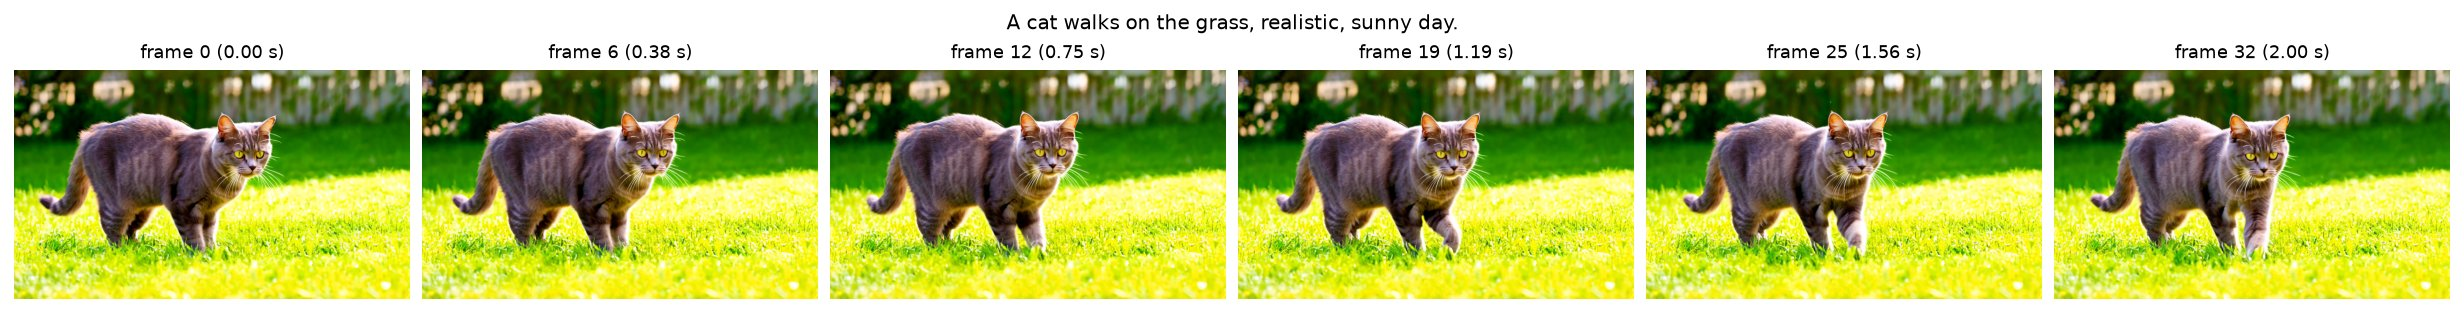

In [4]:
cat = generate("A cat walks on the grass, realistic, sunny day.")
show_frames(cat, title="A cat walks on the grass, realistic, sunny day.")
show_video(cat)

Longer, more specific prompts give more control: the subject, the action, the setting, the light, and the camera.

33 frames of 832 × 480 in 53 s, peak GPU memory 13.5 GB


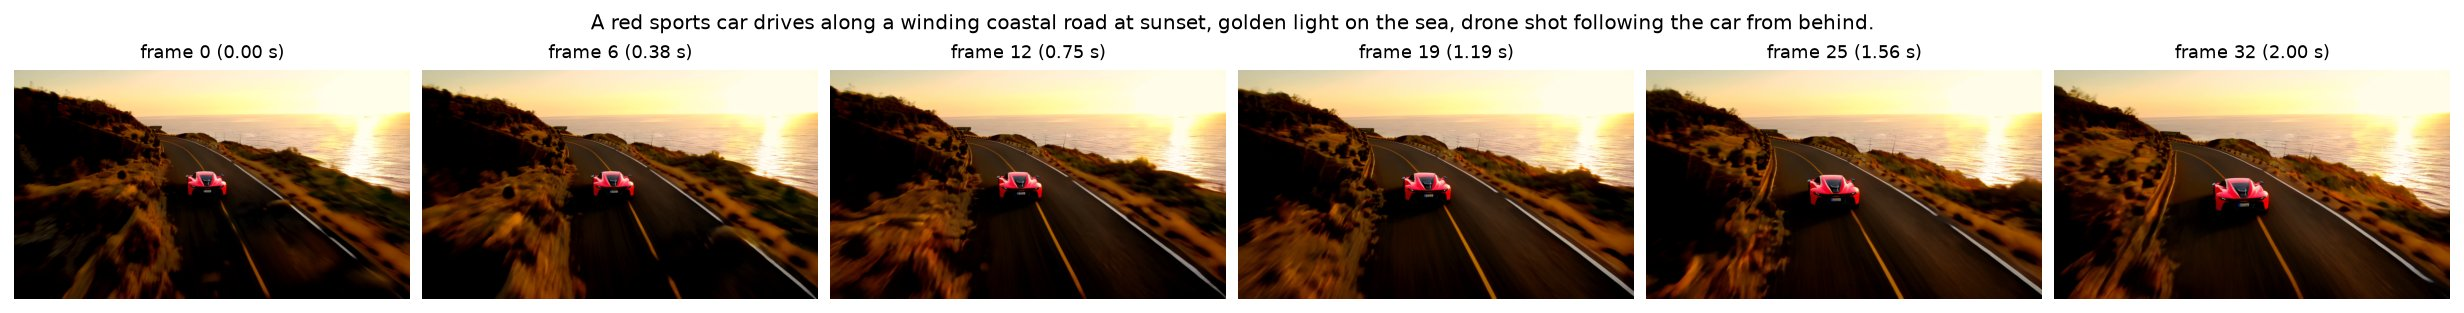

In [5]:
prompt = ("A red sports car drives along a winding coastal road at sunset, golden light on the sea, "
          "drone shot following the car from behind.")
car = generate(prompt, seed=1)
show_frames(car, title=prompt)
show_video(car)

### The seed

The starting noise decides much of the result: the same prompt with a different seed is a different video.

33 frames of 832 × 480 in 53 s, peak GPU memory 13.5 GB


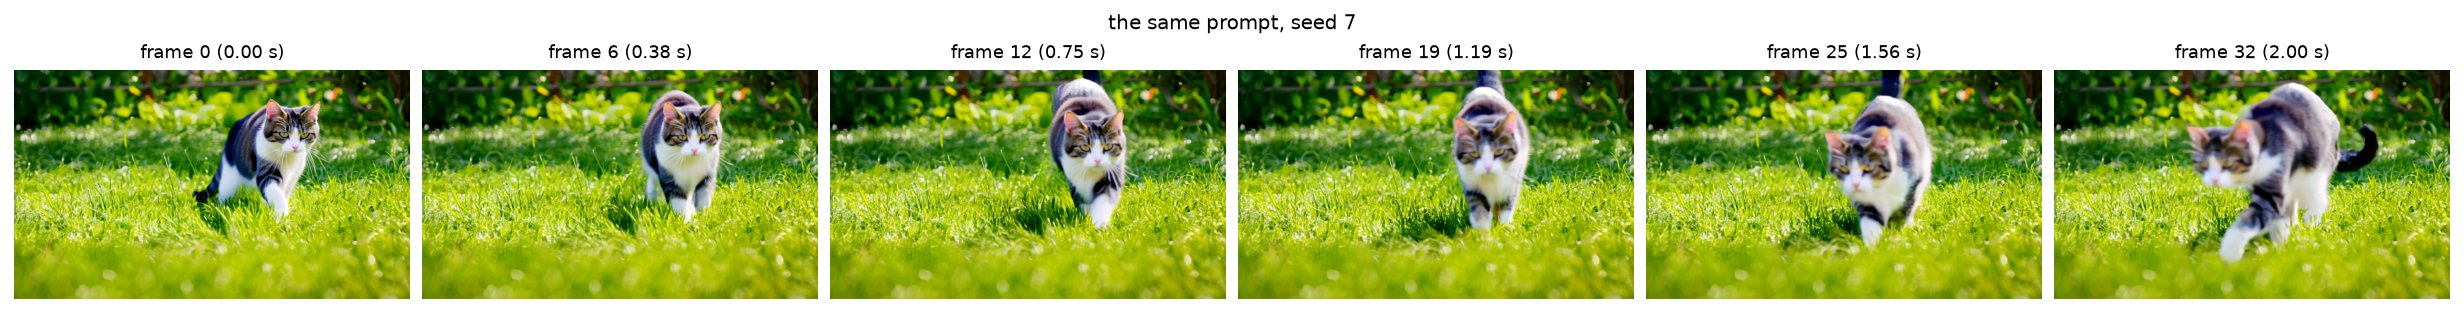

In [6]:
other_cat = generate("A cat walks on the grass, realistic, sunny day.", seed=7)
show_frames(other_cat, title="the same prompt, seed 7")

## Summary

- `WanPipeline.from_pretrained(...)` loads the text encoder, transformer, VAE and scheduler; `enable_model_cpu_offload()`
  makes it fit on a 16 GB GPU;
- `pipe(prompt=..., height=480, width=832, num_frames=4k+1, num_inference_steps=..., guidance_scale=...)` returns the
  frames; the seed of the `generator` makes it reproducible;
- on a T4 GPU (`ml.g4dn.4xlarge`), a 2-second video takes several minutes — longer videos (up to 81 frames) take
  proportionally more.